In [2]:
import json
import random
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt


torch.manual_seed(0)
random.seed(0)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Using device:", device)

Using device: cuda


In [3]:
from sklearn.model_selection import train_test_split

images_path = Path("dataset/images")
data = json.loads(Path("dataset/gt_public.json").read_text())

image_ids = list(data.keys())
train_ids, rest_ids = train_test_split(image_ids, test_size=0.2, random_state=0)
val_ids, test_ids = train_test_split(rest_ids, test_size=0.5, random_state=0)

print(f"Train: {len(train_ids)}, Val: {len(val_ids)}, Test: {len(test_ids)}")


Train: 41470, Val: 5184, Test: 5184


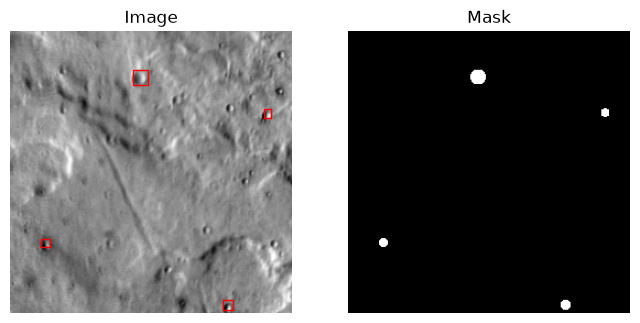

In [4]:
from matplotlib.patches import Rectangle


def make_mask(boxes):
    mask = np.zeros((256, 256), dtype=np.uint8)
    yy, xx = np.mgrid[0:256, 0:256]

    for x, y, w, h in boxes:
        cx = x + w / 2
        cy = y + h / 2
        r = max(w, h) / 2
        inside = (xx + 0.5 - cx) ** 2 + (yy + 0.5 - cy) ** 2 <= r ** 2
        mask[inside] = 1

    return mask


image_id = train_ids[0]
image = plt.imread(images_path / f"{image_id}.png")
mask = make_mask(data[image_id])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

ax1.imshow(image, cmap="gray")
for x, y, w, h in data[image_id]:
    ax1.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=1))
ax1.set_title("Image")
ax1.axis("off")

ax2.imshow(mask, cmap="gray")
ax2.set_title("Mask")
ax2.axis("off")

plt.show()

In [5]:
class CraterDataset(Dataset):
    def __init__(self, image_ids):
        self.image_ids = image_ids

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, i):
        image_id = self.image_ids[i]

        image = Image.open(images_path / f"{image_id}.png").convert("L")
        image = torch.tensor(np.array(image), dtype=torch.float32) / 255.0
        image = image.unsqueeze(0)

        mask = make_mask(data[image_id])
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        return image, mask


train_set = CraterDataset(train_ids)
val_set = CraterDataset(val_ids)
test_set = CraterDataset(test_ids)

train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
val_loader = DataLoader(val_set, batch_size=16, shuffle=False)
test_loader = DataLoader(test_set, batch_size=16, shuffle=False)

images, masks = next(iter(train_loader))
print(images.shape)
print(masks.shape)

torch.Size([16, 1, 256, 256])
torch.Size([16, 1, 256, 256])


In [6]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
    )


class PlainCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            conv_block(1, 32),    # (32, 256, 256)
            conv_block(32, 64),   # (64, 256, 256)
            conv_block(64, 64),   # (64, 256, 256)
            conv_block(64, 32),   # (32, 256, 256)
            nn.Conv2d(32, 1, kernel_size=1),  # (1, 256, 256)
        )

    def forward(self, x):
        return self.layers(x)

In [7]:
run_name = "01-plain-8conv-constant-lr-10epochs"
run_dir = Path("src/cnn") / run_name
run_dir.mkdir(parents=True, exist_ok=True)

model = PlainCNN().to(device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([10.0], device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 10

In [8]:
cutoffs = [0.5]


def evaluate(model, loader):
    model.eval()
    total_loss, n = 0.0, 0
    intersection = {c: 0 for c in cutoffs}
    union = {c: 0 for c in cutoffs}

    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)

            outputs = model(images)
            total_loss += loss_fn(outputs, masks).item() * len(images)
            n += len(images)

            probs = torch.sigmoid(outputs)
            for c in cutoffs:
                preds = (probs > c).float()
                intersection[c] += (preds * masks).sum().item()
                union[c] += ((preds + masks) > 0).sum().item()

    ious = {c: intersection[c] / union[c] for c in cutoffs}
    best_cutoff = max(ious, key=ious.get)
    return total_loss / n, ious[best_cutoff], best_cutoff

In [9]:
import time
from tqdm import tqdm

history = {"train_loss": [], "val_loss": [], "val_iou": [], "best_cutoff": [], "lr": []}
best_iou = 0.0

for epoch in range(epochs):
    model.train()
    running_loss, n = 0.0, 0
    start = time.time()

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs}")
    for images, masks in progress:
        images, masks = images.to(device), masks.to(device)

        outputs = model(images)
        loss = loss_fn(outputs, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(images)
        n += len(images)
        progress.set_postfix(loss=f"{running_loss / n:.4f}")

    train_loss = running_loss / n
    val_loss, val_iou, cutoff = evaluate(model, val_loader)
    lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)
    history["best_cutoff"].append(cutoff)
    history["lr"].append(lr)
    (run_dir / "history.json").write_text(json.dumps(history))

    saved = ""
    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(model.state_dict(), run_dir / "model.pt")
        saved = " (saved)"

    print(f"Epoch {epoch + 1}: train loss {train_loss:.4f} | val loss {val_loss:.4f}, "
          f"val IoU {val_iou:.4f} at cutoff {cutoff} | lr {lr:.6f} | {time.time() - start:.0f}s{saved}")

Epoch 1/10: 100%|██████████| 2592/2592 [02:50<00:00, 15.24it/s, loss=0.4931]


Epoch 1: train loss 0.4931 | val loss 0.4604, val IoU 0.1751 at cutoff 0.5 | lr 0.001000 | 182s (saved)


Epoch 2/10: 100%|██████████| 2592/2592 [02:49<00:00, 15.29it/s, loss=0.4508]


Epoch 2: train loss 0.4508 | val loss 0.4426, val IoU 0.1961 at cutoff 0.5 | lr 0.001000 | 182s (saved)


Epoch 3/10: 100%|██████████| 2592/2592 [02:48<00:00, 15.34it/s, loss=0.4350]


...

Epoch 7/10: 100%|██████████| 2592/2592 [02:48<00:00, 15.37it/s, loss=0.4170]


Epoch 7: train loss 0.4170 | val loss 0.4179, val IoU 0.2207 at cutoff 0.5 | lr 0.001000 | 181s (saved)


Epoch 8/10: 100%|██████████| 2592/2592 [02:49<00:00, 15.33it/s, loss=0.4151]


Epoch 8: train loss 0.4151 | val loss 0.4440, val IoU 0.1636 at cutoff 0.5 | lr 0.001000 | 181s


Epoch 9/10:  71%|███████   | 1832/2592 [01:59<00:48, 15.54it/s, loss=0.4111]IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



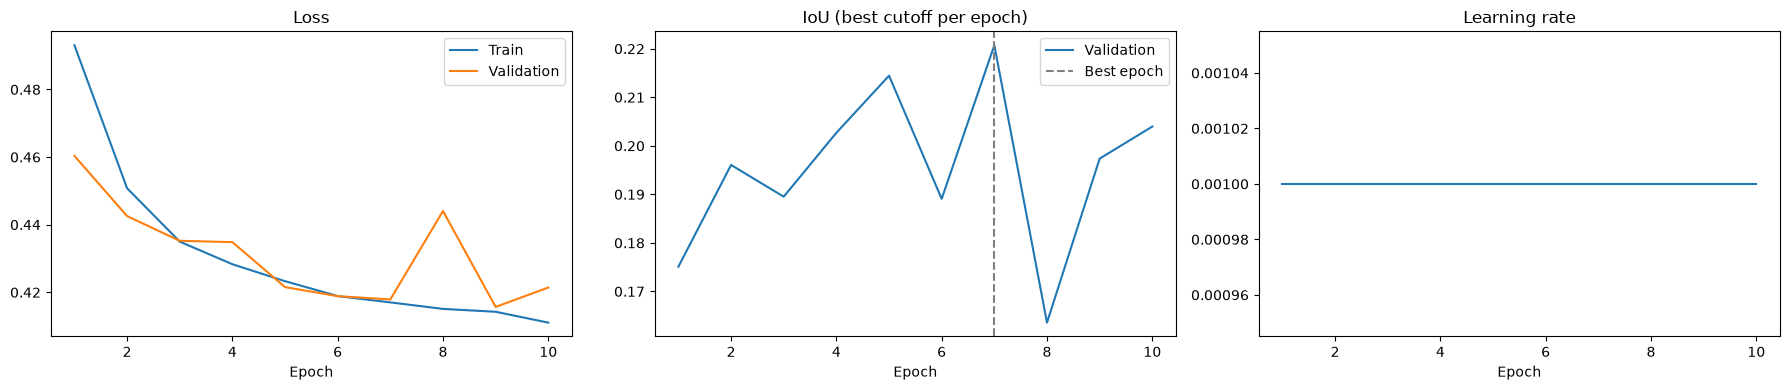

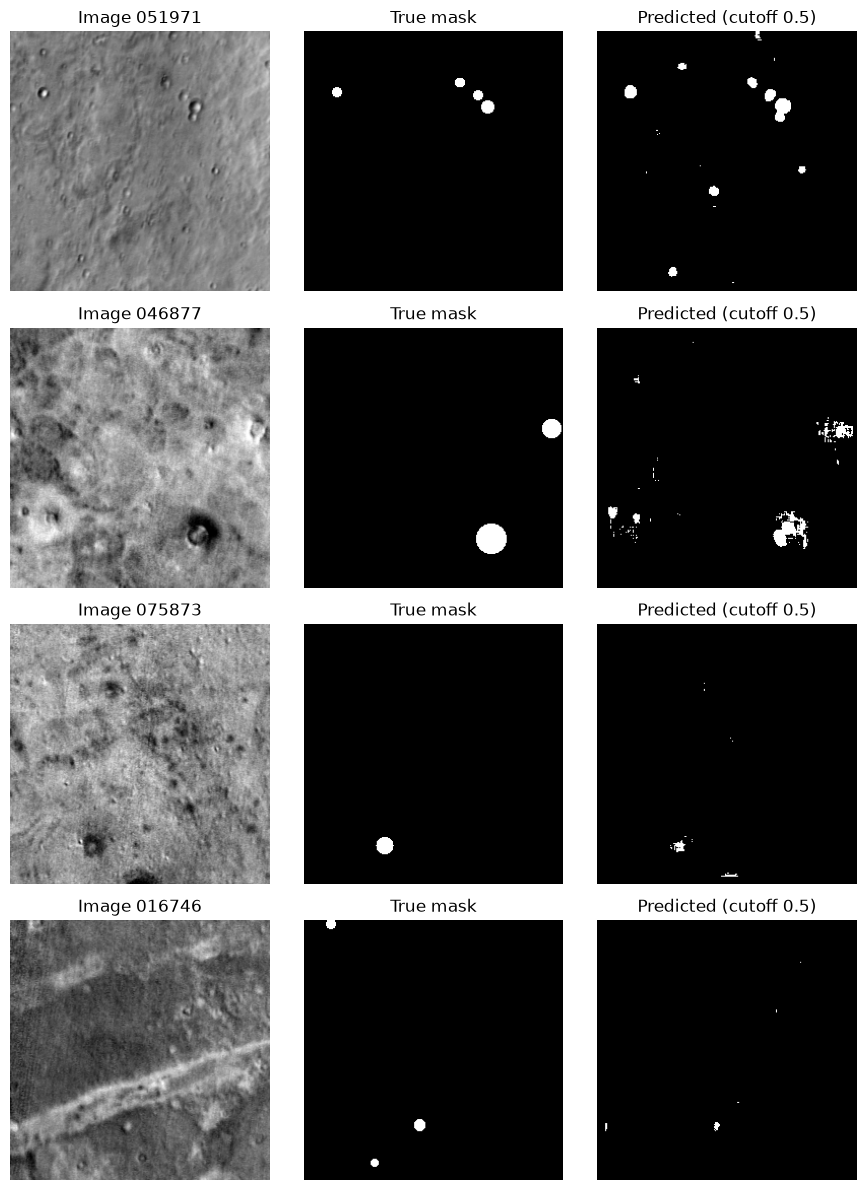

In [11]:
# 1. Notes
best_epoch = history["val_iou"].index(max(history["val_iou"]))
best_cutoff = history["best_cutoff"][best_epoch]

notes = f"""model: PlainCNN (8 conv layers, no pooling, 32-64-64-32 channels), 166,593 parameters
loss: BCEWithLogitsLoss, pos_weight=10
optimizer: Adam, lr=1e-3, constant, no weight decay
batch size: 16
epochs: 10
cutoff: 0.5
best epoch: {best_epoch + 1}
best val IoU: {history["val_iou"][best_epoch]:.4f} at cutoff {best_cutoff}
"""

(run_dir / "notes.txt").write_text(notes)

# 2. Loss, IoU, and learning rate curves
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4))

ax1.plot(epochs_range, history["train_loss"], label="Train")
ax1.plot(epochs_range, history["val_loss"], label="Validation")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.legend()

ax2.plot(epochs_range, history["val_iou"], label="Validation")
ax2.axvline(best_epoch + 1, linestyle="--", color="gray", label="Best epoch")
ax2.set_title("IoU (best cutoff per epoch)")
ax2.set_xlabel("Epoch")
ax2.legend()

ax3.plot(epochs_range, history["lr"])
ax3.set_title("Learning rate")
ax3.set_xlabel("Epoch")

plt.tight_layout()
plt.savefig(run_dir / "curves.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Example predictions from the best saved model
model.load_state_dict(torch.load(run_dir / "model.pt", map_location=device))
model.eval()

fig, axes = plt.subplots(4, 3, figsize=(9, 12))

for i, row in enumerate(axes):
    image, mask = val_set[i]
    with torch.no_grad():
        pred = torch.sigmoid(model(image.unsqueeze(0).to(device)))
    pred = (pred > best_cutoff).float().squeeze().cpu()

    row[0].imshow(image.squeeze(), cmap="gray")
    row[0].set_title(f"Image {val_ids[i]}")
    row[1].imshow(mask.squeeze(), cmap="gray")
    row[1].set_title("True mask")
    row[2].imshow(pred, cmap="gray")
    row[2].set_title(f"Predicted (cutoff {best_cutoff})")
    for ax in row:
        ax.axis("off")

plt.tight_layout()
plt.savefig(run_dir / "predictions.png", dpi=150, bbox_inches="tight")
plt.show()